In [1]:
import os
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

for carpeta in ("img", "modelos", "resultados", "fotos_prueba", "codigo"):
    os.makedirs(carpeta, exist_ok=True)

OJO_DER = [33, 160, 158, 133, 153, 144]    # ojo derecho de la persona (sale a la izquierda de la foto)
OJO_IZQ = [362, 385, 387, 263, 373, 380]

In [4]:
def crear_detector(ruta="modelos/face_landmarker.task"):
    opciones = vision.FaceLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=ruta),
        running_mode=vision.RunningMode.IMAGE,
        num_faces=1,
    )
    return vision.FaceLandmarker.create_from_options(opciones)


def landmarks_de(imagen_bgr, detector):
    rgb = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2RGB)
    res = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    if not res.face_landmarks:
        return None
    h, w = imagen_bgr.shape[:2]
    return np.array([(p.x * w, p.y * h) for p in res.face_landmarks[0]], dtype=np.float32)


def sacar_foto(ruta, espera=3):
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        raise RuntimeError("No puedo abrir la camara")
    for i in range(espera, 0, -1):
        print(f"Foto en {i}...")
        t = time.time()
        while time.time() - t < 1:
            cap.read()                 # seguir leyendo mantiene la imagen fresca y deja que la camara ajuste la luz
    ok, frame = cap.read()
    cap.release()
    if not ok:
        raise RuntimeError("No pude leer ningun fotograma")
    cv2.imwrite(ruta, frame)
    return frame

In [5]:
if all(os.path.exists(f) for f in ["fotos_prueba/ojos_abiertos.jpg", "fotos_prueba/ojos_cerrados.jpg"]):      # si las fotos ya estan, no se repiten
    img_abiertos = cv2.imread("fotos_prueba/ojos_abiertos.jpg")
    img_cerrados = cv2.imread("fotos_prueba/ojos_cerrados.jpg")
else:
    img_abiertos = sacar_foto("fotos_prueba/ojos_abiertos.jpg")      # mira a la cámara con normalidad
    print("Ahora CIERRA los ojos y no los abras hasta que acabe")
    img_cerrados = sacar_foto("fotos_prueba/ojos_cerrados.jpg", espera=4)

W0000 00:00:1795728582.646160  216377 face_landmarker_graph.cc:181] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1795728582.651372  216381 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795728582.661940  216381 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


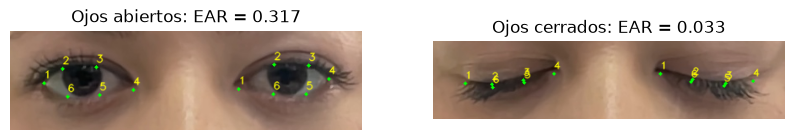

In [7]:
def ear_ojo(pts, idx):
    p1, p2, p3, p4, p5, p6 = pts[idx]
    vertical = np.linalg.norm(p2 - p6) + np.linalg.norm(p3 - p5)
    horizontal = np.linalg.norm(p1 - p4)
    return vertical / (2.0 * horizontal)


def ear(pts):
    return (ear_ojo(pts, OJO_DER) + ear_ojo(pts, OJO_IZQ)) / 2


def dibujar_ojos(img, pts):
    vista = img.copy()
    for idx in (OJO_DER, OJO_IZQ):
        for k, i in enumerate(idx, start=1):
            x, y = int(pts[i][0]), int(pts[i][1])
            cv2.circle(vista, (x, y), 2, (0, 255, 0), -1)
            cv2.putText(vista, str(k), (x, y - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 255), 1, cv2.LINE_AA)
    todos = pts[OJO_DER + OJO_IZQ]
    x1, y1 = todos.min(axis=0).astype(int) - 40
    x2, y2 = todos.max(axis=0).astype(int) + 40
    return vista[max(y1, 0):y2, max(x1, 0):x2]


detector = crear_detector()
pts_abiertos = landmarks_de(img_abiertos, detector)
pts_cerrados = landmarks_de(img_cerrados, detector)
assert pts_abiertos is not None and pts_cerrados is not None, "No veo la cara en alguna foto: repite con mas luz"

fig, ejes = plt.subplots(1, 2, figsize=(10, 3))
for ax, (titulo, img, pts) in zip(ejes, [("Ojos abiertos", img_abiertos, pts_abiertos),
                                         ("Ojos cerrados", img_cerrados, pts_cerrados)]):
    ax.imshow(cv2.cvtColor(dibujar_ojos(img, pts), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{titulo}: EAR = {ear(pts):.3f}")
    ax.axis("off")
plt.savefig("img/p5b_ear_ojos.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
if all(os.path.exists(f) for f in ["fotos_prueba/boca_cerrada.jpg", "fotos_prueba/boca_sonrisa.jpg", "fotos_prueba/boca_bostezo.jpg"]):      # si las fotos ya estan, no se repiten
    img_cerrada = cv2.imread("fotos_prueba/boca_cerrada.jpg")
    img_sonrisa = cv2.imread("fotos_prueba/boca_sonrisa.jpg")
    img_bostezo = cv2.imread("fotos_prueba/boca_bostezo.jpg")
else:
    img_cerrada = sacar_foto("fotos_prueba/boca_cerrada.jpg")                 # boca cerrada, cara normal
    print("Ahora SONRIE ensenando los dientes")
    img_sonrisa = sacar_foto("fotos_prueba/boca_sonrisa.jpg")
    print("Ahora abre la boca MUCHO, como un bostezo (hazlo cuando salga 'Foto en 2')")
    img_bostezo = sacar_foto("fotos_prueba/boca_bostezo.jpg")

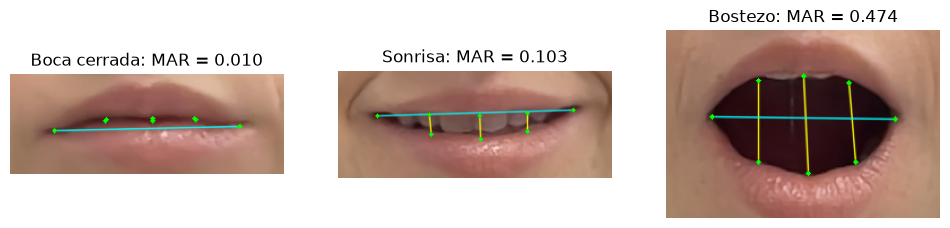

In [9]:
BOCA = [78, 81, 13, 311, 308, 402, 14, 178]


def dist(pts, a, b):
    return float(np.linalg.norm(pts[a] - pts[b]))


def mar(pts):
    vertical = dist(pts, 81, 178) + dist(pts, 13, 14) + dist(pts, 311, 402)
    horizontal = dist(pts, 78, 308)
    return vertical / (3.0 * horizontal)


def dibujar_boca(img, pts):
    vista = img.copy()

    def p(i):
        return int(pts[i][0]), int(pts[i][1])

    for a, b in [(81, 178), (13, 14), (311, 402)]:
        cv2.line(vista, p(a), p(b), (0, 255, 255), 1, cv2.LINE_AA)    # las 3 alturas (amarillo)
    cv2.line(vista, p(78), p(308), (255, 255, 0), 1, cv2.LINE_AA)      # el ancho (cian)
    for i in BOCA:
        cv2.circle(vista, p(i), 2, (0, 255, 0), -1)
    todos = pts[BOCA]
    x1, y1 = todos.min(axis=0).astype(int) - 40
    x2, y2 = todos.max(axis=0).astype(int) + 40
    return vista[max(y1, 0):y2, max(x1, 0):x2]


fotos = [("Boca cerrada", img_cerrada), ("Sonrisa", img_sonrisa), ("Bostezo", img_bostezo)]
fig, ejes = plt.subplots(1, 3, figsize=(12, 3))
for ax, (titulo, img) in zip(ejes, fotos):
    pts = landmarks_de(img, detector)
    assert pts is not None, f"No veo la cara en '{titulo}': repite con mas luz"
    ax.imshow(cv2.cvtColor(dibujar_boca(img, pts), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{titulo}: MAR = {mar(pts):.3f}")
    ax.axis("off")
plt.savefig("img/p5b_mar_boca.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
if all(os.path.exists(f) for f in ["fotos_prueba/cabeza_frente.jpg", "fotos_prueba/cabeza_derecha.jpg", "fotos_prueba/cabeza_izquierda.jpg", "fotos_prueba/cabeza_abajo.jpg"]):      # si las fotos ya estan, no se repiten
    img_frente = cv2.imread("fotos_prueba/cabeza_frente.jpg")
    img_der = cv2.imread("fotos_prueba/cabeza_derecha.jpg")
    img_izq = cv2.imread("fotos_prueba/cabeza_izquierda.jpg")
    img_abajo = cv2.imread("fotos_prueba/cabeza_abajo.jpg")
else:
    img_frente = sacar_foto("fotos_prueba/cabeza_frente.jpg")                         # mira a la camara
    print("Gira la CABEZA a tu derecha (unos 30-40 grados, no solo los ojos)")
    img_der = sacar_foto("fotos_prueba/cabeza_derecha.jpg")
    print("Gira la CABEZA a tu izquierda")
    img_izq = sacar_foto("fotos_prueba/cabeza_izquierda.jpg")
    print("Mira ABAJO, como si miraras el movil")
    img_abajo = sacar_foto("fotos_prueba/cabeza_abajo.jpg")

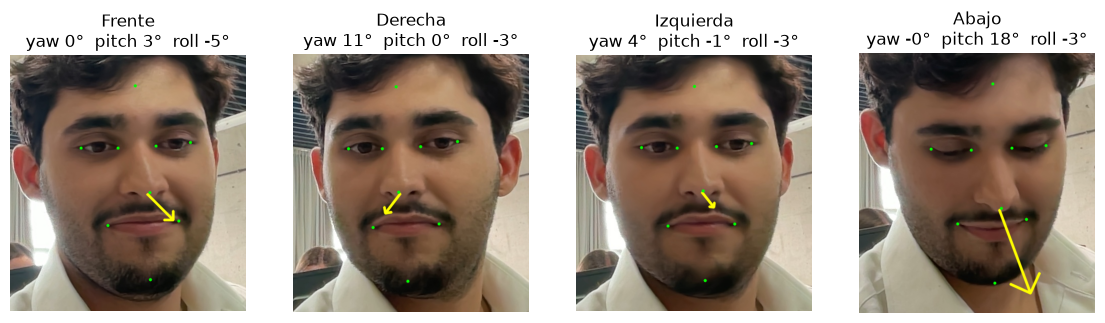

In [11]:
PNP = [1, 152, 33, 263, 133, 362, 61, 291, 10]    # nariz, barbilla, esquinas de los ojos, comisuras, frente
CARA_3D = np.array([                              # esos 9 puntos en una cara 3D de referencia (en cm)
    [0.000, -1.127, 7.476],   # 1   punta de la nariz
    [0.000, -9.403, 4.264],   # 152 barbilla
    [-4.446, 2.664, 3.173],   # 33  esquina externa ojo
    [4.446, 2.664, 3.173],    # 263 esquina externa ojo
    [-1.856, 2.585, 3.758],   # 133 esquina interna ojo
    [1.856, 2.585, 3.758],    # 362 esquina interna ojo
    [-2.456, -4.343, 4.284],  # 61  comisura de la boca
    [2.456, -4.343, 4.284],   # 291 comisura de la boca
    [0.000, 8.262, 4.482],    # 10  frente
]) * np.array([1, -1, -1])                        # al sistema de OpenCV: y hacia abajo, z hacia el fondo


def pose_cabeza(pts, w, h):
    K = np.array([[w, 0, w / 2], [0, w, h / 2], [0, 0, 1]], dtype=np.float64)
    ok, rvec, tvec = cv2.solvePnP(CARA_3D, pts[PNP].astype(np.float64), K, None, flags=cv2.SOLVEPNP_ITERATIVE)
    if not ok or tvec[2, 0] <= 0:                  # la cara no puede estar detras de la camara
        return None
    R, _ = cv2.Rodrigues(rvec)
    pitch = np.degrees(np.arctan2(R[2, 1], R[2, 2]))
    yaw = np.degrees(np.arctan2(-R[2, 0], np.hypot(R[2, 1], R[2, 2])))
    roll = np.degrees(np.arctan2(R[1, 0], R[0, 0]))
    return {"yaw": yaw, "pitch": pitch, "roll": roll, "rvec": rvec, "tvec": tvec, "K": K}


def dibujar_pose(img, pts, pose):
    vista = img.copy()
    nariz = CARA_3D[0]
    fuera = nariz + np.array([0.0, 0.0, -12.0])            # un punto 12 cm delante de la nariz
    p, _ = cv2.projectPoints(np.array([nariz, fuera]), pose["rvec"], pose["tvec"], pose["K"], None)
    a = (int(p[0, 0, 0]), int(p[0, 0, 1]))
    b = (int(p[1, 0, 0]), int(p[1, 0, 1]))
    cv2.arrowedLine(vista, a, b, (0, 255, 255), 3, cv2.LINE_AA, tipLength=0.25)
    for i in PNP:
        cv2.circle(vista, (int(pts[i][0]), int(pts[i][1])), 3, (0, 255, 0), -1)
    x1, y1 = pts.min(axis=0).astype(int) - 60
    x2, y2 = pts.max(axis=0).astype(int) + 60
    return vista[max(y1, 0):y2, max(x1, 0):x2]


fotos = [("Frente", img_frente), ("Derecha", img_der), ("Izquierda", img_izq), ("Abajo", img_abajo)]
fig, ejes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (titulo, img) in zip(ejes, fotos):
    pts = landmarks_de(img, detector)
    assert pts is not None, f"No veo la cara en '{titulo}': repite la foto"
    h, w = img.shape[:2]
    pose = pose_cabeza(pts, w, h)
    assert pose is not None, f"No pude calcular la pose en '{titulo}'"
    ax.imshow(cv2.cvtColor(dibujar_pose(img, pts, pose), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{titulo}\nyaw {pose['yaw']:.0f}°  pitch {pose['pitch']:.0f}°  roll {pose['roll']:.0f}°")
    ax.axis("off")
plt.savefig("img/p5b_pose_cabeza.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
import json
import subprocess

# (segundos, es_accion, texto, etiqueta corta para la grafica)
GUION = [
    (8, False, "Frente, parpadeando normal", "parpadeo"),
    (4, True,  "OJOS CERRADOS",              "ojos"),
    (3, False, "Frente",                     ""),
    (5, True,  "BOSTEZA",                    "bostezo"),
    (3, False, "Frente",                     ""),
    (4, True,  "GIRA a la derecha",          "derecha"),
    (2, False, "Frente",                     ""),
    (4, True,  "GIRA a la izquierda",        "izquierda"),
    (2, False, "Frente",                     ""),
    (4, True,  "MIRA ABAJO (movil)",         "abajo"),
    (2, False, "Frente",                     ""),
    (4, True,  "HABLA o RIETE",              "habla"),
    (3, False, "Frente",                     ""),
]


def pitido(accion):
    sonido = "/System/Library/Sounds/Glass.aiff" if accion else "/System/Library/Sounds/Ping.aiff"
    try:
        subprocess.Popen(["afplay", sonido])
    except FileNotFoundError:
        pass


def grabar_clip(ruta_video, ruta_json, guion, espera=5):
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        raise RuntimeError("No puedo abrir la camara")
    # cuenta atras; de paso medimos a cuantos fotogramas por segundo va la camara
    t0, n = time.time(), 0
    for i in range(espera, 0, -1):
        print(f"Empieza en {i}... ponte de frente")
        t = time.time()
        while time.time() - t < 1:
            ok, frame = cap.read()
            n += int(ok)
    fps = n / (time.time() - t0)
    h, w = frame.shape[:2]
    salida = cv2.VideoWriter(ruta_video, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

    tiempos, segmentos = [], []
    inicio = time.time()
    for dur, accion, texto, etiqueta in guion:
        t_seg = time.time() - inicio
        segmentos.append({"inicio": t_seg, "accion": accion, "texto": texto, "etiqueta": etiqueta})
        pitido(accion)
        print(f"[{t_seg:4.1f} s] {texto}")
        fin = time.time() + dur
        while time.time() < fin:
            ok, frame = cap.read()
            if ok:
                salida.write(frame)
                tiempos.append(time.time() - inicio)
    cap.release()
    salida.release()
    with open(ruta_json, "w") as f:
        json.dump({"fps": fps, "tiempos": tiempos, "segmentos": segmentos}, f)
    print(f"Listo: {len(tiempos)} fotogramas, {fps:.1f} fps -> {ruta_video}")


if not os.path.exists("resultados/clip_prueba.json"):         # si el clip ya esta grabado, no se repite
    grabar_clip("resultados/clip_prueba.mp4", "resultados/clip_prueba.json", GUION)

Cara detectada en el 100.0 % de los fotogramas


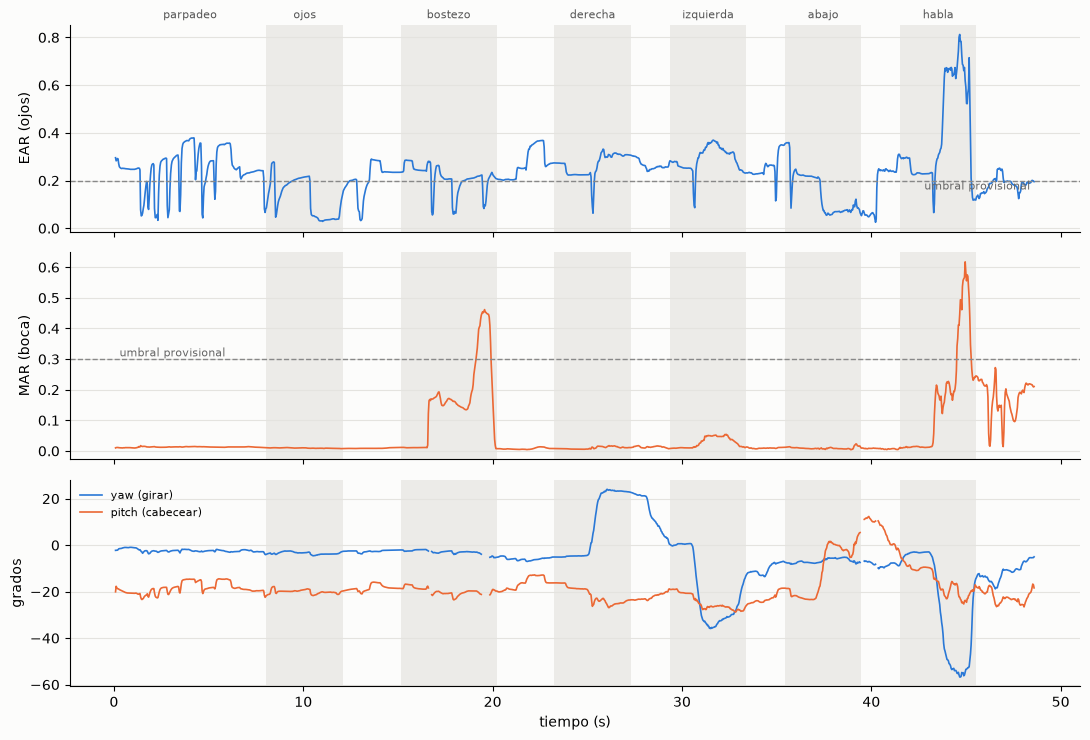

In [13]:
AZUL, NARANJA, SUP = "#2a78d6", "#eb6834", "#fcfcfb"


def crear_detector_video(ruta="modelos/face_landmarker.task"):
    opciones = vision.FaceLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=ruta),
        running_mode=vision.RunningMode.VIDEO,
        num_faces=1,
    )
    return vision.FaceLandmarker.create_from_options(opciones)


def analizar_clip(ruta_video, ruta_json, detector_v):
    with open(ruta_json) as f:
        datos = json.load(f)
    tiempos = datos["tiempos"]
    n = len(tiempos)
    sen = {k: np.full(n, np.nan) for k in ("ear", "mar", "yaw", "pitch", "roll")}
    cap = cv2.VideoCapture(ruta_video)
    ultimo_ts, leidos = -1, 0
    for i in range(n):
        ok, frame = cap.read()
        if not ok:
            break
        leidos += 1
        h, w = frame.shape[:2]
        ts = max(int(tiempos[i] * 1000), ultimo_ts + 1)      # MediaPipe exige tiempos crecientes
        ultimo_ts = ts
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        res = detector_v.detect_for_video(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb), ts)
        if res.face_landmarks:
            pts = np.array([(p.x * w, p.y * h) for p in res.face_landmarks[0]], dtype=np.float32)
            sen["ear"][i] = ear(pts)
            sen["mar"][i] = mar(pts)
            pose = pose_cabeza(pts, w, h)
            if pose is not None:
                sen["yaw"][i], sen["pitch"][i], sen["roll"][i] = pose["yaw"], pose["pitch"], pose["roll"]
        if i % 200 == 0:
            print(f"fotograma {i}/{n}")
    cap.release()
    return np.array(tiempos[:leidos]), {k: v[:leidos] for k, v in sen.items()}, datos["segmentos"]


def dibujar_senales(t, sen, segmentos, ruta="img/p5b_senales_clip.png"):
    fig, ejes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True, facecolor=SUP)
    fines = [s["inicio"] for s in segmentos[1:]] + [t[-1]]
    for ax in ejes:
        ax.set_facecolor(SUP)
        ax.grid(axis="y", color="#e4e3df")
        ax.spines[["top", "right"]].set_visible(False)
        for seg, fin in zip(segmentos, fines):
            if seg["accion"]:
                ax.axvspan(seg["inicio"], fin, color="#d9d8d3", alpha=0.45, lw=0)
    for seg, fin in zip(segmentos, fines):
        if seg["etiqueta"]:
            ejes[0].text((seg["inicio"] + fin) / 2, 1.02, seg["etiqueta"], ha="center", va="bottom",
                         fontsize=8, color="#555", transform=ejes[0].get_xaxis_transform())
    ejes[0].plot(t, sen["ear"], color=AZUL, lw=1.2)
    ejes[0].axhline(0.2, color="#888", ls="--", lw=1)
    ejes[0].text(t[-1], 0.2, "umbral provisional ", ha="right", va="top", fontsize=8, color="#666")
    ejes[0].set_ylabel("EAR (ojos)")
    ejes[1].plot(t, sen["mar"], color=NARANJA, lw=1.2)
    ejes[1].axhline(0.3, color="#888", ls="--", lw=1)
    ejes[1].text(t[0], 0.3, " umbral provisional", ha="left", va="bottom", fontsize=8, color="#666")
    ejes[1].set_ylabel("MAR (boca)")
    ejes[2].plot(t, sen["yaw"], color=AZUL, lw=1.2, label="yaw (girar)")
    ejes[2].plot(t, sen["pitch"], color=NARANJA, lw=1.2, label="pitch (cabecear)")
    ejes[2].set_ylabel("grados")
    ejes[2].legend(frameon=False, loc="upper left", fontsize=8)
    ejes[2].set_xlabel("tiempo (s)")
    fig.tight_layout()
    fig.savefig(ruta, dpi=150, facecolor=SUP)
    plt.show()


if os.path.exists("resultados/clip_senales.npz"):                    # si el clip ya esta analizado, no se repite
    d = np.load("resultados/clip_senales.npz")
    t, sen = d["t"], {k: d[k] for k in ("ear", "mar", "yaw", "pitch", "roll")}
    with open("resultados/clip_prueba.json") as f:
        segmentos = json.load(f)["segmentos"]
else:
    detector_v = crear_detector_video()
    t, sen, segmentos = analizar_clip("resultados/clip_prueba.mp4", "resultados/clip_prueba.json", detector_v)
    detector_v.close()
    np.savez("resultados/clip_senales.npz", t=t, **sen)
print(f"Cara detectada en el {100 * np.mean(~np.isnan(sen['ear'])):.1f} % de los fotogramas")
dibujar_senales(t, sen, segmentos)

Tu cara normal: {'ear': 0.251, 'mar': 0.013, 'yaw': -2.424, 'pitch': -18.826}


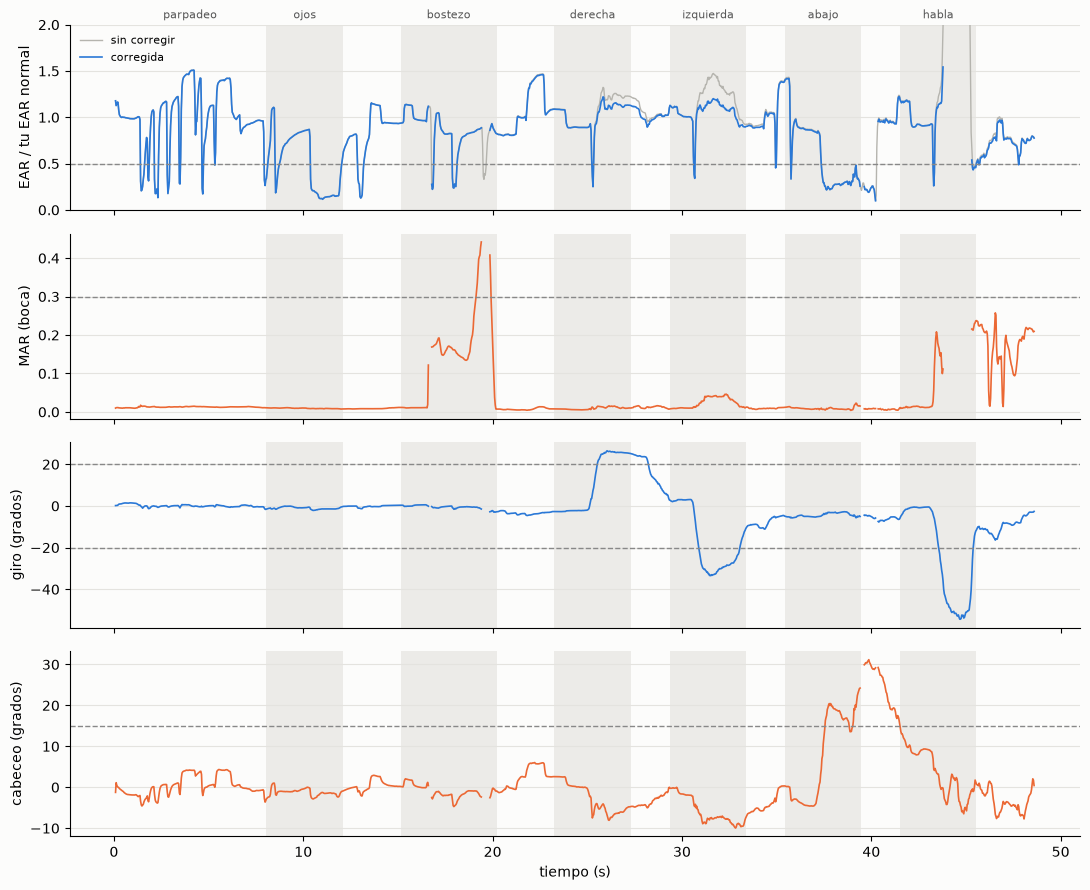

In [14]:
UMBRAL_OJOS = 0.5     # EAR_rel por debajo de esto = ojo cerrado
UMBRAL_BOCA = 0.3     # MAR por encima de esto = boca muy abierta
UMBRAL_GIRO = 20      # grados de giro respecto a tu postura normal
UMBRAL_ABAJO = 15     # grados mirando abajo respecto a tu postura normal

d = np.load("resultados/clip_senales.npz")
t = d["t"]
sen = {k: d[k] for k in ("ear", "mar", "yaw", "pitch", "roll")}
with open("resultados/clip_prueba.json") as f:
    segmentos = json.load(f)["segmentos"]


def calibrar(t, sen, hasta=8.0):
    """Tu cara normal: la mediana de cada senal en los primeros segundos (mirando al frente)."""
    m = t < hasta
    return {k: float(np.nanmedian(sen[k][m])) for k in ("ear", "mar", "yaw", "pitch")}


def normalizar(sen, base, max_yaw=40):
    c = np.cos(np.radians(sen["yaw"]))                    # al girar, el ancho se acorta y EAR/MAR se inflan
    with np.errstate(invalid="ignore"):
        fiable = np.abs(sen["yaw"]) <= max_yaw
    return {
        "ear_sin_corregir": sen["ear"] / base["ear"],
        "ear_rel": np.where(fiable, sen["ear"] * c, np.nan) / base["ear"],
        "mar": np.where(fiable, sen["mar"] * c, np.nan),
        "yaw_rel": sen["yaw"] - base["yaw"],
        "pitch_rel": sen["pitch"] - base["pitch"],
    }


def dibujar_normalizadas(t, norm, segmentos, ruta="img/p5b_senales_normalizadas.png"):
    paneles = [  # (clave, nombre del eje, color, lineas de umbral)
        ("ear_rel", "EAR / tu EAR normal", AZUL, [UMBRAL_OJOS]),
        ("mar", "MAR (boca)", NARANJA, [UMBRAL_BOCA]),
        ("yaw_rel", "giro (grados)", AZUL, [UMBRAL_GIRO, -UMBRAL_GIRO]),
        ("pitch_rel", "cabeceo (grados)", NARANJA, [UMBRAL_ABAJO]),
    ]
    fig, ejes = plt.subplots(len(paneles), 1, figsize=(11, 9), sharex=True, facecolor=SUP)
    fines = [s["inicio"] for s in segmentos[1:]] + [t[-1]]
    for ax, (clave, nombre, color, umbrales) in zip(ejes, paneles):
        ax.set_facecolor(SUP)
        ax.grid(axis="y", color="#e4e3df")
        ax.spines[["top", "right"]].set_visible(False)
        for seg, fin in zip(segmentos, fines):
            if seg["accion"]:
                ax.axvspan(seg["inicio"], fin, color="#d9d8d3", alpha=0.45, lw=0)
        if clave == "ear_rel":
            ax.plot(t, norm["ear_sin_corregir"], color="#b5b4ae", lw=1, label="sin corregir")
        ax.plot(t, norm[clave], color=color, lw=1.2, label="corregida" if clave == "ear_rel" else None)
        for u in umbrales:
            ax.axhline(u, color="#888", ls="--", lw=1)
        ax.set_ylabel(nombre)
    ejes[0].legend(frameon=False, loc="upper left", fontsize=8)
    ejes[0].set_ylim(0, 2)
    for seg, fin in zip(segmentos, fines):
        if seg["etiqueta"]:
            ejes[0].text((seg["inicio"] + fin) / 2, 1.02, seg["etiqueta"], ha="center", va="bottom",
                         fontsize=8, color="#555", transform=ejes[0].get_xaxis_transform())
    ejes[-1].set_xlabel("tiempo (s)")
    fig.tight_layout()
    fig.savefig(ruta, dpi=150, facecolor=SUP)
    plt.show()


base = calibrar(t, sen)
print("Tu cara normal:", {k: round(v, 3) for k, v in base.items()})
norm = normalizar(sen, base)
dibujar_normalizadas(t, norm, segmentos)

In [15]:
UMBRAL_BOCA_ABIERTA = 0.15     # MAR por encima de esto = boca abierta (tu bostezo pasa 2 s en 0.15-0.2)


def eventos(mask, t):
    """Tramos seguidos donde mask es True. Devuelve una lista de (segundo en que empieza, duracion en s)."""
    res, inicio = [], None
    for i, activo in enumerate(mask):
        if activo and inicio is None:
            inicio = t[i]
        if not activo and inicio is not None:
            res.append((inicio, t[i] - inicio))
            inicio = None
    if inicio is not None:
        res.append((inicio, t[-1] - inicio))
    return res


def mostrar_eventos(nombre, mask):
    ev = eventos(mask, t)
    print(f"{nombre}: {len(ev)} eventos")
    for a, d in ev:
        print(f"   desde {a:5.1f} s   dura {d:4.1f} s")


with np.errstate(invalid="ignore"):                     # los NaN (sin cara o giro > 40) cuentan como False
    mostrar_eventos(f"OJOS CERRADOS  (EAR_rel < {UMBRAL_OJOS})", norm["ear_rel"] < UMBRAL_OJOS)
    mostrar_eventos(f"BOCA ABIERTA   (MAR > {UMBRAL_BOCA_ABIERTA})", norm["mar"] > UMBRAL_BOCA_ABIERTA)
    mostrar_eventos(f"GIRO           (|yaw| > {UMBRAL_GIRO} grados)", np.abs(norm["yaw_rel"]) > UMBRAL_GIRO)
    mostrar_eventos(f"MIRA ABAJO     (pitch > {UMBRAL_ABAJO} grados)", norm["pitch_rel"] > UMBRAL_ABAJO)

OJOS CERRADOS  (EAR_rel < 0.5): 23 eventos
   desde   1.4 s   dura  0.2 s
   desde   1.8 s   dura  0.1 s
   desde   2.1 s   dura  0.2 s
   desde   2.8 s   dura  0.1 s
   desde   3.5 s   dura  0.1 s
   desde   4.7 s   dura  0.1 s
   desde   5.3 s   dura  0.0 s
   desde   7.9 s   dura  0.2 s
   desde   8.5 s   dura  0.2 s
   desde  10.4 s   dura  1.7 s
   desde  12.9 s   dura  0.3 s
   desde  16.8 s   dura  0.1 s
   desde  17.9 s   dura  0.3 s
   desde  25.3 s   dura  0.1 s
   desde  30.6 s   dura  0.1 s
   desde  34.9 s   dura  0.0 s
   desde  35.8 s   dura  0.0 s
   desde  37.4 s   dura  2.1 s
   desde  39.6 s   dura  0.6 s
   desde  43.3 s   dura  0.1 s
   desde  45.3 s   dura  0.2 s
   desde  45.7 s   dura  0.0 s
   desde  47.8 s   dura  0.0 s
BOCA ABIERTA   (MAR > 0.15): 10 eventos
   desde  16.8 s   dura  0.5 s
   desde  17.5 s   dura  0.7 s
   desde  18.8 s   dura  0.7 s
   desde  19.9 s   dura  0.2 s
   desde  43.4 s   dura  0.3 s
   desde  43.7 s   dura  0.0 s
   desde  45.3 s  

 10.9 s  AVISO  ojos      dura  1.1 s
 11.4 s  ALERTA ojos      dura  0.6 s
 18.3 s  AVISO  bostezo   dura  1.1 s
 26.6 s  AVISO  giro      dura  1.9 s
 27.6 s  ALERTA giro      dura  1.0 s
 32.0 s  AVISO  giro      dura  1.4 s
 32.9 s  ALERTA giro      dura  0.4 s
 38.6 s  AVISO  abajo     dura  3.2 s
 39.6 s  ALERTA abajo     dura  2.2 s
 44.6 s  AVISO  giro      dura  1.1 s
 45.6 s  ALERTA giro      dura  0.1 s


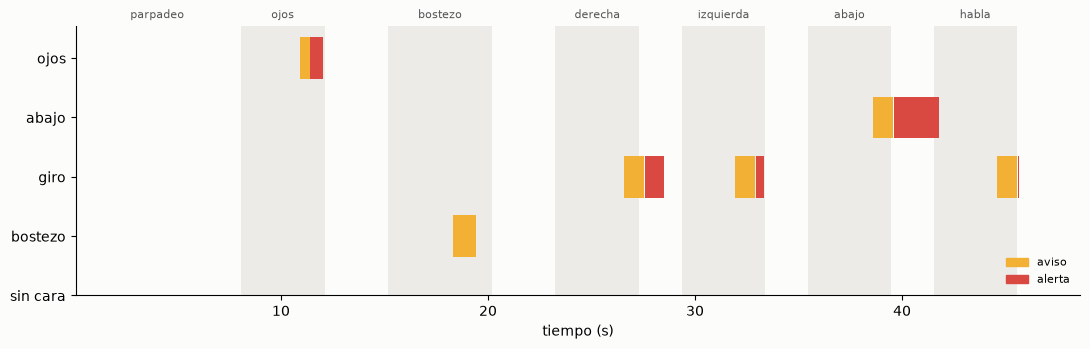

In [16]:
from matplotlib.patches import Patch

# nombre: (segundos para AVISO, segundos para ALERTA, hueco de datos que se tolera en segundos)
REGLAS = {
    "ojos":     (0.5, 1.0, 0.0),
    "abajo":    (1.0, 2.0, 0.3),
    "giro":     (1.0, 2.0, 0.3),
    "bostezo":  (1.5, np.inf, 0.0),
    "sin cara": (1.0, 2.0, 0.0),
}
AMBAR, ROJO = "#f2b035", "#d94841"
UMBRAL_BOCA_CERRADA = 0.10      # la boca se da por cerrada por debajo de esto



def duracion_continua(mask, t, hueco=0.0):
    """Para cada fotograma: segundos que lleva seguida la condicion (0 si no se cumple).
    Un corte de datos de menos de 'hueco' segundos no reinicia la cuenta."""
    dur = np.zeros(len(t))
    inicio, ultimo = None, None
    for i, activo in enumerate(mask):
        if activo:
            if inicio is None:
                inicio = t[i]
            ultimo = t[i]
        elif inicio is not None and t[i] - ultimo > hueco:
            inicio = None
        if inicio is not None:
            dur[i] = t[i] - inicio
    return dur


def con_histeresis(x, on, off):
    """True desde que x supera 'on' hasta que baja de 'off'. Evita que la senal parpadee alrededor de un solo umbral."""
    mask = np.zeros(len(x), dtype=bool)
    estado = False
    for i, v in enumerate(x):
        if np.isnan(v):
            estado = False
        elif v > on:
            estado = True
        elif v < off:
            estado = False
        mask[i] = estado
    return mask


def calcular_niveles(t, sen, norm):
    with np.errstate(invalid="ignore"):                  # los NaN cuentan como False
        abajo = norm["pitch_rel"] > UMBRAL_ABAJO
        activas = {
            "ojos": (norm["ear_rel"] < UMBRAL_OJOS) & ~abajo,    # con la cabeza abajo, el EAR no cuenta
            "abajo": abajo,
            "giro": np.abs(norm["yaw_rel"]) > UMBRAL_GIRO,
            "bostezo": con_histeresis(norm["mar"], UMBRAL_BOCA_ABIERTA, UMBRAL_BOCA_CERRADA),
            "sin cara": np.isnan(sen["ear"]),
        }
    nivel = {}
    for nombre, mask in activas.items():
        t_aviso, t_alerta, hueco = REGLAS[nombre]
        dur = duracion_continua(mask, t, hueco)
        nivel[nombre] = np.where(dur >= t_alerta, 2, np.where(dur >= t_aviso, 1, 0))
    return nivel


def mostrar_alertas(t, nivel):
    filas = []
    for nombre, niv in nivel.items():
        for n, etiqueta in ((1, "AVISO"), (2, "ALERTA")):
            for a, d in eventos(niv >= n, t):
                filas.append((a, etiqueta, nombre, d))
    for a, etiqueta, nombre, d in sorted(filas):
        print(f"{a:5.1f} s  {etiqueta:6s} {nombre:9s} dura {d:4.1f} s")


def dibujar_alertas(t, nivel, segmentos, ruta="img/p5b_alertas.png"):
    nombres = list(nivel)
    fig, ax = plt.subplots(figsize=(11, 3.6), facecolor=SUP)
    ax.set_facecolor(SUP)
    ax.spines[["top", "right"]].set_visible(False)
    fines = [s["inicio"] for s in segmentos[1:]] + [t[-1]]
    for seg, fin in zip(segmentos, fines):
        if seg["accion"]:
            ax.axvspan(seg["inicio"], fin, color="#d9d8d3", alpha=0.45, lw=0)
        if seg["etiqueta"]:
            ax.text((seg["inicio"] + fin) / 2, 1.02, seg["etiqueta"], ha="center", va="bottom",
                    fontsize=8, color="#555", transform=ax.get_xaxis_transform())
    for k, nombre in enumerate(nombres):
        y = len(nombres) - 1 - k
        ax.fill_between(t, y, y + 0.7, where=nivel[nombre] == 1, color=AMBAR, step="post", lw=0)
        ax.fill_between(t, y, y + 0.7, where=nivel[nombre] == 2, color=ROJO, step="post", lw=0)
    ax.set_yticks([len(nombres) - 1 - k + 0.35 for k in range(len(nombres))])
    ax.set_yticklabels(nombres)
    ax.set_xlim(t[0], t[-1])
    ax.set_xlabel("tiempo (s)")
    ax.legend(handles=[Patch(color=AMBAR, label="aviso"), Patch(color=ROJO, label="alerta")],
              frameon=False, loc="lower right", fontsize=8)
    fig.tight_layout()
    fig.savefig(ruta, dpi=150, facecolor=SUP)
    plt.show()


nivel = calcular_niveles(t, sen, norm)
mostrar_alertas(t, nivel)
dibujar_alertas(t, nivel, segmentos)

## Monitor en directo

`codigo/monitor_conductor.py` hace lo mismo que las celdas anteriores, pero con la cámara y fotograma a fotograma:

1. Durante los 8 primeros segundos se **calibra la cara** .
2. Después aplica las mismas reglas (ojos, abajo, giro, bostezo, sin cara) con el mismo tiempo para AVISO y para ALERTA, pero mirando solo al pasado.
3. Muestra ATENTO / AVISO / ALERTA con el motivo, suena una alarma  y apunta cada cambio en `resultados/registro_monitor.csv`.

La primera celda escribe el archivo, la segunda comprueba que en directo salen **las mismas alertas** que en el análisis del clip, y la tercera lo lanza con la cámara. Teclas: `c` calibrar otra vez, `m` sonido sí/no, `ESC` o `q` salir.

In [17]:
%%writefile codigo/monitor_conductor.py
"""
PROTOTIPO B: Monitor de atencion del conductor (en directo)

Vigila la cara con MediaPipe y avisa si el conductor parece distraido o con sueno:
ojos cerrados, cabeza hacia abajo, mirada a otro lado, bostezo o cara fuera de camara.
Al arrancar se calibra con la cara de cada persona (8 s mirando al frente), asi que
los umbrales se miden respecto a "tu normal" y no a valores fijos.

Uso:    python codigo/monitor_conductor.py
        python codigo/monitor_conductor.py --grabar resultados/demo_monitor.mp4      (guarda tambien el video)
Teclas: c = calibrar otra vez     m = sonido si/no     ESC o q = salir
"""
import argparse
import csv
import math
import os
import subprocess
import time
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

RAIZ = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))   # carpeta Practica5_VC

# ---------- puntos de la malla de la cara (los mismos del cuaderno) ----------
OJO_DER = [33, 160, 158, 133, 153, 144]
OJO_IZQ = [362, 385, 387, 263, 373, 380]
BOCA = [78, 81, 13, 311, 308, 402, 14, 178]
PNP = [1, 152, 33, 263, 133, 362, 61, 291, 10]   # nariz, barbilla, esquinas de ojos, comisuras, frente
CARA_3D = np.array([
    [0.000, -1.127, 7.476],   # 1
    [0.000, -9.403, 4.264],   # 152
    [-4.446, 2.664, 3.173],   # 33
    [4.446, 2.664, 3.173],    # 263
    [-1.856, 2.585, 3.758],   # 133
    [1.856, 2.585, 3.758],    # 362
    [-2.456, -4.343, 4.284],  # 61
    [2.456, -4.343, 4.284],   # 291
    [0.000, 8.262, 4.482],    # 10
]) * np.array([1, -1, -1])                        # al sistema de OpenCV: y hacia abajo, z hacia el fondo

# ---------- umbrales y reglas (los mismos del cuaderno) ----------
UMBRAL_OJOS = 0.5            # EAR_rel por debajo de esto = ojos cerrados
UMBRAL_ABAJO = 15            # grados mirando abajo respecto a tu postura normal
UMBRAL_GIRO = 20             # grados de giro respecto a tu postura normal
UMBRAL_BOCA_ABIERTA = 0.15   # MAR por encima de esto = boca abierta
UMBRAL_BOCA_CERRADA = 0.10   # la boca se da por cerrada por debajo de esto (histeresis)
MAX_YAW = 40                 # con mas giro, EAR y MAR dejan de ser fiables
SEGUNDOS_CALIBRACION = 8.0

# nombre: (segundos para AVISO, segundos para ALERTA, hueco de datos que se tolera en segundos)
REGLAS = {
    "ojos":     (0.5, 1.0, 0.0),
    "abajo":    (1.0, 2.0, 0.3),
    "giro":     (1.0, 2.0, 0.3),
    "bostezo":  (1.5, math.inf, 0.0),
    "sin cara": (1.0, 2.0, 0.0),
}
TEXTO_MOTIVO = {
    "ojos": "ojos cerrados",
    "abajo": "mirando abajo",
    "giro": "mirando a otro lado",
    "bostezo": "bostezo",
    "sin cara": "no veo la cara",
}


# ---------- las senales de un fotograma (identicas a las del cuaderno) ----------
def ear_ojo(pts, idx):
    p1, p2, p3, p4, p5, p6 = pts[idx]
    vertical = np.linalg.norm(p2 - p6) + np.linalg.norm(p3 - p5)
    horizontal = np.linalg.norm(p1 - p4)
    return vertical / (2.0 * horizontal)


def ear(pts):
    return (ear_ojo(pts, OJO_DER) + ear_ojo(pts, OJO_IZQ)) / 2


def dist(pts, a, b):
    return float(np.linalg.norm(pts[a] - pts[b]))


def mar(pts):
    vertical = dist(pts, 81, 178) + dist(pts, 13, 14) + dist(pts, 311, 402)
    horizontal = dist(pts, 78, 308)
    return vertical / (3.0 * horizontal)


def pose_cabeza(pts, w, h):
    """(yaw, pitch, roll) en grados; None si la solucion no vale."""
    K = np.array([[w, 0, w / 2], [0, w, h / 2], [0, 0, 1]], dtype=np.float64)
    ok, rvec, tvec = cv2.solvePnP(CARA_3D, pts[PNP].astype(np.float64), K, None, flags=cv2.SOLVEPNP_ITERATIVE)
    if not ok or tvec[2, 0] <= 0:                  # la cara no puede estar detras de la camara
        return None
    R, _ = cv2.Rodrigues(rvec)
    pitch = np.degrees(np.arctan2(R[2, 1], R[2, 2]))
    yaw = np.degrees(np.arctan2(-R[2, 0], np.hypot(R[2, 1], R[2, 2])))
    roll = np.degrees(np.arctan2(R[1, 0], R[0, 0]))
    return yaw, pitch, roll


def medir(pts, w, h):
    """Las 5 senales de UN fotograma. Si no hay cara (pts es None), todo nan."""
    s = {k: np.nan for k in ("ear", "mar", "yaw", "pitch", "roll")}
    if pts is None:
        return s
    s["ear"] = ear(pts)
    s["mar"] = mar(pts)
    pose = pose_cabeza(pts, w, h)
    if pose is not None:
        s["yaw"], s["pitch"], s["roll"] = pose
    return s


# ---------- calibracion y reglas ----------
def calibrar(muestras, n_total):
    """Devuelve (base, aviso). base = tu cara normal (mediana de cada senal).
    Si algo no cuadra, base es None y aviso dice que hacer."""
    con_pose = [m for m in muestras if not math.isnan(m["yaw"])]
    if len(muestras) < 0.6 * n_total or len(con_pose) < 0.5 * n_total:
        return None, "Casi no te veo: mira a la camara"
    base = {}
    for k in ("ear", "mar", "yaw", "pitch"):
        valores = [m[k] for m in muestras if not math.isnan(m[k])]
        base[k] = float(np.median(valores))
    if base["ear"] < 0.12:
        return None, "Abre los ojos y mira a la camara"
    if abs(base["yaw"]) > 25:
        return None, "Mira de frente a la camara"
    return base, None


def normalizar_frame(s, base, max_yaw=MAX_YAW):
    """Lo mismo que 'normalizar' del cuaderno, pero con un solo fotograma."""
    yaw = s["yaw"]
    fiable = not math.isnan(yaw) and abs(yaw) <= max_yaw
    c = math.cos(math.radians(yaw)) if not math.isnan(yaw) else math.nan   # al girar, EAR y MAR se inflan
    return {
        "ear_rel": float(s["ear"]) * c / base["ear"] if fiable else math.nan,
        "mar": float(s["mar"]) * c if fiable else math.nan,
        "yaw_rel": yaw - base["yaw"],
        "pitch_rel": s["pitch"] - base["pitch"],
    }


class Regla:
    """Cuenta cuanto tiempo lleva seguida una condicion. Es 'duracion_continua' del cuaderno,
    pero fotograma a fotograma: solo mira el pasado, que es lo unico que se tiene en directo."""

    def __init__(self, t_aviso, t_alerta, hueco):
        self.t_aviso, self.t_alerta, self.hueco = t_aviso, t_alerta, hueco
        self.inicio = None
        self.ultimo = None

    def actualizar(self, t, activo):
        if activo:
            if self.inicio is None:
                self.inicio = t
            self.ultimo = t
        elif self.inicio is not None and t - self.ultimo > self.hueco:
            self.inicio = None
        duracion = t - self.inicio if self.inicio is not None else 0.0
        if duracion >= self.t_alerta:
            return 2
        if duracion >= self.t_aviso:
            return 1
        return 0


class Monitor:
    """Junta las reglas. Recibe las senales de cada fotograma y devuelve el nivel de cada regla
    (0 = bien, 1 = AVISO, 2 = ALERTA)."""

    def __init__(self, base):
        self.base = base
        self.reglas = {nombre: Regla(*params) for nombre, params in REGLAS.items()}
        self.boca_abierta = False                                 # memoria de la histeresis
        # La histeresis de la boca tambien se adapta a la cara: si en reposo tu boca ya marca algo,
        # "cerrada" tiene que quedar por encima de ese valor. Con la boca de la prueba (0.013) salen
        # 0.10 y 0.15, los mismos del cuaderno.
        self.mar_off = max(UMBRAL_BOCA_CERRADA, base["mar"] + 0.03)
        self.mar_on = max(UMBRAL_BOCA_ABIERTA, self.mar_off + 0.05)

    def evaluar(self, t, s):
        n = normalizar_frame(s, self.base)
        abajo = n["pitch_rel"] > UMBRAL_ABAJO                     # con nan da False
        if math.isnan(n["mar"]):
            self.boca_abierta = False
        elif n["mar"] > self.mar_on:
            self.boca_abierta = True
        elif n["mar"] < self.mar_off:
            self.boca_abierta = False
        activas = {
            "ojos": bool(n["ear_rel"] < UMBRAL_OJOS) and not abajo,    # con la cabeza abajo, el EAR no cuenta
            "abajo": bool(abajo),
            "giro": bool(abs(n["yaw_rel"]) > UMBRAL_GIRO),
            "bostezo": self.boca_abierta,
            "sin cara": bool(math.isnan(s["ear"])),
        }
        niveles = {nombre: self.reglas[nombre].actualizar(t, activas[nombre]) for nombre in REGLAS}
        return niveles, n


# ---------- sonido y registro ----------
SONIDOS = {1: "/System/Library/Sounds/Ping.aiff", 2: "/System/Library/Sounds/Basso.aiff"}


class Alarma:
    """Suena al pasar a un nivel mas alto; en ALERTA se repite cada 1.5 s. Usa afplay (Mac)."""

    def __init__(self):
        self.activa = True              # la tecla m lo cambia
        self.disponible = True          # False si no hay afplay (no es un Mac)
        self.nivel_ant = 0
        self.ultimo = -99.0
        self.proceso = None

    def actualizar(self, t, nivel):
        sube = nivel > self.nivel_ant
        toca = sube or (nivel == 2 and t - self.ultimo >= 1.5)
        self.nivel_ant = nivel
        sonando = self.proceso is not None and self.proceso.poll() is None
        if sube and sonando:
            self.proceso.terminate()    # el sonido nuevo tapa al anterior
            sonando = False
        if toca and nivel > 0 and self.activa and self.disponible and not sonando:
            try:
                self.proceso = subprocess.Popen(["afplay", SONIDOS[nivel]])
            except FileNotFoundError:
                self.disponible = False
            self.ultimo = t


class Registro:
    """Apunta en un csv cuando cada regla cambia de nivel (para poder revisar la sesion luego)."""

    def __init__(self, ruta=os.path.join(RAIZ, "resultados", "registro_monitor.csv")):
        os.makedirs(os.path.dirname(ruta), exist_ok=True)
        self.f = open(ruta, "w", newline="")
        self.w = csv.writer(self.f)
        self.w.writerow(["segundos", "regla", "nivel"])
        self.anterior = {}

    def anotar(self, t, niveles):
        for nombre, nivel in niveles.items():
            if nivel != self.anterior.get(nombre, 0):
                self.w.writerow([f"{t:.1f}", nombre, ("ok", "AVISO", "ALERTA")[nivel]])
                self.f.flush()
                self.anterior[nombre] = nivel

    def cerrar(self):
        self.f.close()


# ---------- camara y detector ----------
def crear_detector(ruta=os.path.join(RAIZ, "modelos", "face_landmarker.task")):
    opciones = vision.FaceLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=ruta),
        running_mode=vision.RunningMode.VIDEO,
        num_faces=1,
    )
    return vision.FaceLandmarker.create_from_options(opciones)


def detectar(detector, frame, ts_ms):
    """Devuelve los 478 puntos de la cara en pixeles, o None si no hay cara."""
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    imagen = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    res = detector.detect_for_video(imagen, ts_ms)
    if not res.face_landmarks:
        return None
    h, w = frame.shape[:2]
    return np.array([(p.x * w, p.y * h) for p in res.face_landmarks[0]], dtype=np.float32)


# ---------- dibujo ----------
FUENTE = cv2.FONT_HERSHEY_SIMPLEX
COLOR_NIVEL = {0: (80, 175, 60), 1: (40, 170, 245), 2: (60, 60, 220)}      # BGR: verde, ambar, rojo
GRIS = (95, 95, 95)
NOMBRE_NIVEL = {0: "ATENTO", 1: "AVISO", 2: "ALERTA"}


def texto(frame, s, org, escala=0.7, color=(255, 255, 255), grosor=2):
    """Texto con borde negro para que se lea sobre cualquier fondo."""
    cv2.putText(frame, s, org, FUENTE, escala, (0, 0, 0), grosor + 2, cv2.LINE_AA)
    cv2.putText(frame, s, org, FUENTE, escala, color, grosor, cv2.LINE_AA)


def dibujar_puntos(frame, pts):
    for i in OJO_DER + OJO_IZQ + BOCA:
        cv2.circle(frame, (int(pts[i][0]), int(pts[i][1])), 2, (0, 255, 0), -1)


def dibujar_calibracion(frame, progreso, aviso):
    w = frame.shape[1]
    cv2.rectangle(frame, (0, 0), (w, 44), (150, 100, 40), -1)
    texto(frame, "CALIBRANDO: mira a la camara, sin hablar", (15, 31), 0.8)
    cv2.rectangle(frame, (15, 60), (w - 15, 76), (60, 60, 60), -1)
    cv2.rectangle(frame, (15, 60), (15 + int((w - 30) * min(progreso, 1.0)), 76), (255, 200, 80), -1)
    if aviso:
        texto(frame, aviso, (15, 110), 0.7, (0, 200, 255))


def dibujar_estado(frame, niveles):
    h, w = frame.shape[:2]
    nivel = max(niveles.values())
    mensaje = NOMBRE_NIVEL[nivel]
    if nivel > 0:
        motivos = [TEXTO_MOTIVO[nombre] for nombre, v in niveles.items() if v == nivel]
        mensaje += ": " + ", ".join(motivos)
    cv2.rectangle(frame, (0, 0), (w, 44), COLOR_NIVEL[nivel], -1)
    texto(frame, mensaje, (15, 31), 0.85)
    if nivel == 2:
        cv2.rectangle(frame, (0, 0), (w - 1, h - 1), COLOR_NIVEL[2], 8)


def grados(x):
    return "--" if math.isnan(x) else f"{round(x):+d}"


def dibujar_numeros(frame, n):
    """Las senales respecto a tu normal: ojos 1.00 = igual que siempre, giro y cabeceo 0 = como al calibrar."""
    ear_rel = "--" if math.isnan(n["ear_rel"]) else f"{n['ear_rel']:.2f}"
    boca = "--" if math.isnan(n["mar"]) else f"{n['mar']:.2f}"
    texto(frame, f"ojos    {ear_rel}", (15, 75), 0.55)
    texto(frame, f"boca    {boca}", (15, 98), 0.55)
    texto(frame, f"giro    {grados(n['yaw_rel'])}", (15, 121), 0.55)
    texto(frame, f"cabeceo {grados(n['pitch_rel'])}", (15, 144), 0.55)


def dibujar_reglas(frame, niveles):
    """Una etiqueta por regla: gris si todo bien, ambar en AVISO, roja en ALERTA."""
    h = frame.shape[0]
    x = 15
    for nombre, nivel in niveles.items():
        (ancho, _), _ = cv2.getTextSize(nombre, FUENTE, 0.5, 1)
        color = COLOR_NIVEL[nivel] if nivel > 0 else GRIS
        cv2.rectangle(frame, (x, h - 52), (x + ancho + 16, h - 28), color, -1)
        cv2.putText(frame, nombre, (x + 8, h - 35), FUENTE, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
        x += ancho + 24


def cerrar_todo(cap, detector, writer=None, registro=None):
    """Libera todo. Se puede llamar varias veces sin problema."""
    cap.release()
    detector.close()
    if writer is not None:
        writer.release()
    if registro is not None:
        registro.cerrar()
    cv2.destroyAllWindows()
    for _ in range(4):
        cv2.waitKey(1)          # en Mac, sin estas pasadas la ventana puede quedarse abierta


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--grabar", metavar="VIDEO.mp4", help="guarda tambien el video de la demo")
    args = parser.parse_args()

    detector = crear_detector()
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        cerrar_todo(cap, detector)
        raise SystemExit("No puedo abrir la camara")

    alarma, registro = Alarma(), Registro()
    monitor, writer = None, None                    # monitor es None mientras se calibra
    muestras, n_cal, t_cal, aviso = [], 0, None, None
    t0 = time.time()
    ultimo_ts = -1
    fps, t_ant = 0.0, time.time()
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            frame = cv2.flip(frame, 1)                     # efecto espejo (el signo del giro se invierte, da igual: usamos |giro|)
            h, w = frame.shape[:2]

            t = time.time() - t0
            ts = max(int(t * 1000), ultimo_ts + 1)         # MediaPipe exige tiempos crecientes
            ultimo_ts = ts
            pts = detectar(detector, frame, ts)
            s = medir(pts, w, h)
            if pts is not None:
                dibujar_puntos(frame, pts)

            if monitor is None:                            # fase 1: calibrar
                if t_cal is None:
                    t_cal = t
                n_cal += 1
                if not math.isnan(s["ear"]):
                    muestras.append(s)
                progreso = (t - t_cal) / SEGUNDOS_CALIBRACION
                if progreso >= 1:
                    base, aviso = calibrar(muestras, n_cal)
                    if base is None:                       # algo fallo: a repetir
                        muestras, n_cal, t_cal = [], 0, t
                    else:
                        monitor = Monitor(base)
                        print("Tu cara normal:", {k: round(v, 3) for k, v in base.items()})
                        if args.grabar:
                            fps_real = n_cal / (t - t_cal)
                            writer = cv2.VideoWriter(args.grabar, cv2.VideoWriter_fourcc(*"mp4v"), fps_real, (w, h))
                dibujar_calibracion(frame, progreso, aviso)
            else:                                          # fase 2: vigilar
                niveles, n = monitor.evaluar(t, s)
                registro.anotar(t, niveles)
                alarma.actualizar(t, max(niveles.values()))
                dibujar_estado(frame, niveles)
                dibujar_numeros(frame, n)
                dibujar_reglas(frame, niveles)

            ahora = time.time()
            fps = 0.9 * fps + 0.1 / max(ahora - t_ant, 1e-6)
            t_ant = ahora
            texto(frame, f"{fps:.0f} fps   sonido: {'si' if alarma.activa else 'no'}", (w - 230, h - 15), 0.5)
            if writer is not None:
                writer.write(frame)

            cv2.imshow("Monitor del conductor", frame)
            tecla = cv2.waitKey(1) & 0xFF
            if tecla in (27, ord("q")):                    # ESC o q
                break
            if tecla == ord("m"):
                alarma.activa = not alarma.activa
            if tecla == ord("c"):                          # volver a calibrar
                monitor, muestras, n_cal, t_cal, aviso = None, [], 0, None, None
                alarma.nivel_ant = 0
    except KeyboardInterrupt:
        print("Interrumpido con Ctrl+C")
    finally:
        cerrar_todo(cap, detector, writer, registro)       # se ejecuta SIEMPRE, haya error o no
        print("Camara liberada.")
        if args.grabar:
            print("Video guardado en", args.grabar)


if __name__ == "__main__":
    main()


Overwriting codigo/monitor_conductor.py


In [ ]:
import importlib
import sys
sys.path.insert(0, "codigo")      # el monitor esta en la carpeta codigo/
import monitor_conductor
importlib.reload(monitor_conductor)          # por si has cambiado el archivo

# Reproducimos el clip fotograma a fotograma por el monitor y comparamos con 'nivel' (celda 13)
mon = monitor_conductor.Monitor(base)
en_directo = {nombre: [] for nombre in nivel}
for i in range(len(t)):
    senales = {k: sen[k][i] for k in sen}
    niveles, _ = mon.evaluar(float(t[i]), senales)
    for nombre, valor in niveles.items():
        en_directo[nombre].append(valor)

total = 0
for nombre in nivel:
    distintos = int(np.sum(np.array(en_directo[nombre]) != nivel[nombre]))
    total += distintos
    print(f"{nombre:9s} fotogramas distintos: {distintos}")
print("El monitor en directo da las mismas alertas que el analisis del clip" if total == 0
      else "Hay diferencias: revisa que los umbrales de la celda 13 y los de monitor_conductor.py coinciden")

ojos      fotogramas distintos: 0
abajo     fotogramas distintos: 0
giro      fotogramas distintos: 0
bostezo   fotogramas distintos: 0
sin cara  fotogramas distintos: 0
El monitor en directo da las mismas alertas que el analisis del clip


In [18]:
import subprocess
import sys

# Abre una ventana con la camara: calibra 8 s mirando al frente y despues vigila.
# ESC o q para salir. Con --grabar se guarda ademas el video de la demo.
r = subprocess.run([sys.executable, "codigo/monitor_conductor.py", "--grabar", "resultados/demo_monitor.mp4"],
                   capture_output=True, text=True)
for linea in (r.stdout + r.stderr).splitlines():
    if "W0000" not in linea and "INFO:" not in linea:
        print(linea)

Tu cara normal: {'ear': 0.309, 'mar': 0.03, 'yaw': 1.146, 'pitch': -10.397}
Camara liberada.
Video guardado en resultados/demo_monitor.mp4


## Pruebas de robustez

Cada prueba dura unos 45 s con la cámara: calibra 8 s, 7 s sin hacer nada raro (aquí se cuentan las **falsas alarmas**) y después sigue un guion con pitidos (cerrar los ojos, girar, mirar abajo y bostezar). Al terminar apunta en `resultados/robustez.csv` si el monitor detectó cada cosa. Si no logra ni calibrarse, también queda apuntado, porque eso es un resultado.

Se hace una celda por condición: antes de lanzar cada una, prepara la condición.

In [19]:
%%writefile codigo/robustez.py
"""
PRUEBA DE ROBUSTEZ del monitor del conductor

Una sesion de unos 45 s con la camara en una condicion concreta (normal, poca luz, lejos, gafas...).
Calibra 8 s mirando al frente y despues sigue un guion (ojos cerrados, girar, mirar abajo, bostezar).
Al terminar apunta en resultados/robustez.csv que ha detectado el monitor en esa condicion.

Uso:  python codigo/robustez.py normal
      python codigo/robustez.py "poca luz"
"""
import csv
import math
import os
import subprocess
import sys
import time
import cv2
from monitor_conductor import (RAIZ, SEGUNDOS_CALIBRACION, Monitor, calibrar, crear_detector, detectar, medir,
                               dibujar_estado, dibujar_numeros, dibujar_puntos, dibujar_reglas,
                               cerrar_todo, texto)

# (segundo en que empieza, es una accion, instruccion en pantalla)
GUION = [
    (8.0,  False, "NORMAL: no hagas nada raro, parpadea con naturalidad"),
    (15.0, True,  "CIERRA LOS OJOS"),
    (20.0, False, "Mira al frente"),
    (22.0, True,  "GIRA la cabeza a un lado (unos 30-40 grados)"),
    (27.0, False, "Mira al frente"),
    (29.0, True,  "MIRA ABAJO, como si miraras el movil"),
    (34.0, False, "Mira al frente"),
    (36.0, True,  "BOSTEZA (abre mucho la boca)"),
    (41.0, False, "Mira al frente"),
]
FIN = 43.0
GRACIA = 1.5          # segundos extra tras cada accion: la gente reacciona 1-2 s despues del pitido
CAMPOS = ["condicion", "fps", "cara_%", "falsas_alarmas", "ojos", "giro", "abajo", "bostezo"]


def instruccion(t):
    actual = GUION[0]
    for paso in GUION:
        if t >= paso[0]:
            actual = paso
    return actual


def pitido():
    try:
        subprocess.Popen(["afplay", "/System/Library/Sounds/Ping.aiff"])
    except FileNotFoundError:
        pass


def alcanzo(historial, regla, nivel, desde, hasta):
    """True si la regla llego a 'nivel' en algun momento entre 'desde' y 'hasta' (segundos)."""
    return any(n[regla] >= nivel for t, n in historial if desde <= t < hasta)


def evaluar(condicion, historial, fps, pct_cara):
    """Una fila de resultados a partir de lo que paso en la sesion."""
    # falsas alarmas = veces que una regla salta (de 0 a AVISO o mas) mientras no se hace nada raro
    falsas = 0
    previo = {}
    for t, niveles in historial:
        for regla, nivel in niveles.items():
            if 8.0 <= t < 15.0 and nivel >= 1 and previo.get(regla, 0) == 0:
                falsas += 1
            previo[regla] = nivel
    ventana = {paso[2].split()[0]: (paso[0], GUION[i + 1][0]) for i, paso in enumerate(GUION[:-1]) if paso[1]}
    (o1, o2), (g1, g2), (a1, a2), (b1, b2) = ventana["CIERRA"], ventana["GIRA"], ventana["MIRA"], ventana["BOSTEZA"]
    si_no = lambda ok: "si" if ok else "no"
    return {
        "condicion": condicion, "fps": f"{fps:.0f}", "cara_%": f"{pct_cara:.0f}", "falsas_alarmas": falsas,
        "ojos": si_no(alcanzo(historial, "ojos", 2, o1, o2 + GRACIA)),
        "giro": si_no(alcanzo(historial, "giro", 1, g1, g2 + GRACIA)),
        "abajo": si_no(alcanzo(historial, "abajo", 1, a1, a2 + GRACIA)),
        "bostezo": si_no(alcanzo(historial, "bostezo", 1, b1, b2 + GRACIA)),
    }


def guardar(fila, ruta=os.path.join(RAIZ, "resultados", "robustez.csv")):
    """Guarda la fila; si esa condicion ya estaba, se sustituye por la nueva."""
    filas = {}
    if os.path.exists(ruta):
        with open(ruta, newline="") as f:
            filas = {r["condicion"]: r for r in csv.DictReader(f)}
    filas[fila["condicion"]] = fila
    with open(ruta, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=CAMPOS)
        w.writeheader()
        w.writerows(filas.values())


def main():
    if len(sys.argv) < 2:
        raise SystemExit('Uso: python codigo/robustez.py "nombre de la condicion"')
    condicion = sys.argv[1]
    detector = crear_detector()
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        cerrar_todo(cap, detector)
        raise SystemExit("No puedo abrir la camara")

    monitor, muestras, historial = None, [], []
    n_frames, n_con_cara, paso_ant = 0, 0, None
    t0 = time.time()
    ultimo_ts = -1
    resultado = None
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            frame = cv2.flip(frame, 1)
            h, w = frame.shape[:2]
            t = time.time() - t0
            ts = max(int(t * 1000), ultimo_ts + 1)
            ultimo_ts = ts
            pts = detectar(detector, frame, ts)
            s = medir(pts, w, h)
            n_frames += 1
            n_con_cara += pts is not None
            if pts is not None:
                dibujar_puntos(frame, pts)

            if monitor is None:                               # primeros 8 s: calibrar
                if not math.isnan(s["ear"]):
                    muestras.append(s)
                cv2.rectangle(frame, (0, 0), (w, 44), (150, 100, 40), -1)
                texto(frame, f"CALIBRANDO ({condicion}): mira al frente, sin hablar", (15, 31), 0.7)
                if t >= SEGUNDOS_CALIBRACION:
                    base, aviso = calibrar(muestras, n_frames)
                    if base is None:
                        print(f"NO CALIBRA en la condicion '{condicion}': {aviso}")
                        resultado = {"condicion": condicion, "fps": f"{n_frames / t:.0f}",
                                     "cara_%": f"{100 * n_con_cara / n_frames:.0f}", "falsas_alarmas": "-",
                                     "ojos": "-", "giro": "-", "abajo": "-", "bostezo": "-"}
                        break
                    monitor = Monitor(base)
            else:
                niveles, n = monitor.evaluar(t, s)
                historial.append((t, niveles))
                dibujar_estado(frame, niveles)
                dibujar_numeros(frame, n)
                dibujar_reglas(frame, niveles)
                paso = instruccion(t)
                if paso is not paso_ant:
                    pitido()
                    paso_ant = paso
                texto(frame, paso[2], (15, h - 70), 0.7, (0, 255, 255) if paso[1] else (255, 255, 255))
                if t >= FIN:
                    break

            cv2.imshow("Prueba de robustez", frame)
            if cv2.waitKey(1) & 0xFF in (27, ord("q")):
                print("Prueba cancelada")
                break
    except KeyboardInterrupt:
        print("Interrumpido con Ctrl+C")
    finally:
        cerrar_todo(cap, detector)

    if resultado is None and historial and historial[-1][0] >= FIN:
        resultado = evaluar(condicion, historial, n_frames / (time.time() - t0), 100 * n_con_cara / n_frames)
    if resultado is not None:
        guardar(resultado)
        print("Resultado:", resultado)


if __name__ == "__main__":
    main()


Overwriting codigo/robustez.py


In [20]:
import subprocess
import sys


def probar(condicion):
    r = subprocess.run([sys.executable, "codigo/robustez.py", condicion], capture_output=True, text=True)
    for linea in (r.stdout + r.stderr).splitlines():
        if "W0000" not in linea and "INFO:" not in linea:
            print(linea)

In [35]:
probar("normal")        # sentada de frente, con buena luz

Resultado: {'condicion': 'normal', 'fps': '16', 'cara_%': '100', 'falsas_alarmas': 0, 'ojos': 'si', 'giro': 'si', 'abajo': 'no', 'bostezo': 'si'}


In [34]:
probar("poca luz")      # con poca luz

NO CALIBRA en la condicion 'poca luz': Casi no te veo: mira a la camara
Resultado: {'condicion': 'poca luz', 'fps': '16', 'cara_%': '98', 'falsas_alarmas': '-', 'ojos': '-', 'giro': '-', 'abajo': '-', 'bostezo': '-'}


In [28]:
probar("lejos")         # lejos de la camara

NO CALIBRA en la condicion 'lejos': Casi no te veo: mira a la camara
Resultado: {'condicion': 'lejos', 'fps': '29', 'cara_%': '0', 'falsas_alarmas': '-', 'ojos': '-', 'giro': '-', 'abajo': '-', 'bostezo': '-'}


In [32]:
probar("gafas")         # con las gafas 

Resultado: {'condicion': 'gafas', 'fps': '22', 'cara_%': '95', 'falsas_alarmas': 0, 'ojos': 'si', 'giro': 'si', 'abajo': 'no', 'bostezo': 'no'}


In [31]:
probar("ladeada")       # con inclinacion de cabeza 

Resultado: {'condicion': 'ladeada', 'fps': '17', 'cara_%': '100', 'falsas_alarmas': 0, 'ojos': 'si', 'giro': 'no', 'abajo': 'si', 'bostezo': 'no'}


In [23]:
import csv

with open("resultados/robustez.csv", newline="") as f:
    filas = list(csv.DictReader(f))
campos = list(filas[0].keys())
print("| " + " | ".join(campos) + " |")
print("|" + "---|" * len(campos))
for fila in filas:
    print("| " + " | ".join(fila[c] for c in campos) + " |")

| condicion | fps | cara_% | falsas_alarmas | ojos | giro | abajo | bostezo |
|---|---|---|---|---|---|---|---|
| normal | 19 | 99 | - | - | - | - | - |
